# 16d — HMM market regimes as model features

Notebook 16c found that market regimes exist and that auction volume responds to them, but that the best model may already capture most of it. This notebook measures directly how much LightGBM improves when it is given regime features from a hidden Markov model (HMM).

**HMM design (fixed before running):**
- **Inputs:** four market-wide daily inputs from `regime_utils.py`: activity, realized volatility, auction-share deviation and drawdown. Each uses data only up to t−1. Fear premium and dispersion were dropped in 16c.
- **Fitting:** a Gaussian HMM with full covariances, fitted **inside each training window only**. The tuning phase uses the tuning window and the refit phase uses the refit window, so validation and test years never influence the HMM. Inputs are standardized with that window's mean and standard deviation, and each state count gets 10 random restarts.
- **Number of states:** chosen by **BIC over 1–6 states**. Because the inputs are smoothed and strongly autocorrelated, BIC tends to favor many states, so a **fixed 3-state** HMM is run as a sensitivity check.
- **No look-ahead:** features use **forward-filtered** probabilities P(state on t | inputs up to t). hmmlearn's built-in `predict_proba` uses future data and is not used. A check below confirms that deleting later data doesn't change earlier features.
- **Features (the same 9 whatever the number of states):** probability of the calmest state, probability of the most stressed state, rank of the most likely state, uncertainty (entropy), days since the regime last changed, and the expected value of each of the four inputs under the current state probabilities.

**Model comparison.** All candidates use the same rows ("large" tier: 750K tune / 150K validation / 1M refit), the 58 + 3 ratio features, the residual target, the leaf grid {15, 31, 63} and the same folds as `lgbm_61_ratios_large` in 16a:

| Candidate | Added features |
|---|---|
| `lgbm_control` | none: should reproduce 16a's `lgbm_61_ratios_large` |
| `lgbm_plus_regime_inputs` | the 4 raw HMM inputs: is any gain from the HMM, or just from the inputs? |
| `lgbm_plus_hmm_bic` | 9 HMM features, BIC-chosen state count |
| `lgbm_plus_hmm_k3` | 9 HMM features, fixed 3 states |
| `lgbm_plus_inputs_and_hmm_bic` | raw inputs + HMM features |

The pass rule is the same as before: a mean development (2022–2024) log RMSE improvement of at least 0.002, no development year worse by more than 0.002, and a paired date-block bootstrap. Every candidate is judged against the control and against the frozen ridge.

In [1]:
import json
import logging
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

import challenger_utils as cu
import regime_utils as ru

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*eval_set.*deprecated.*")
logging.getLogger("hmmlearn").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

OUT = cu.output_dir("16d_hmm_regime_features")
LGBM_16A = cu.EDA / "16a_lightgbm_improvements"  # full-run results, also used in smoke mode
RESTARTS = 3 if cu.SMOKE else 10
print(f"Outputs: {OUT}; smoke mode: {cu.SMOKE}")

inputs = ru.build_regime_inputs(cu.con, cu.PROJECT_ROOT)
REGIME_INPUT_FEATURES = [f"regime_{c}" for c in ru.HMM_INPUTS]
HMM3_FEATURES = [f.replace("hmm_", "hmm3_") for f in ru.HMM_FEATURES]

Outputs: /Users/alisapriyadarsini/Downloads/capstone/blackrock_workspace/outputs/eda/16d_hmm_regime_features; smoke mode: False


## Fit the HMMs fold by fold

For each test year t: the tuning-phase HMM is fitted on inputs from t−6 to t−2 (the tuning window), and the refit-phase HMM on t−5 to t−1 (the refit window).

In [2]:
def phase_window(test_year, phase):
    first = test_year - 6 if phase == "tune" else test_year - 5
    return f"{first}-01-01", f"{first + 4}-12-31"

EXTRA, BIC_ROWS, PROFILES = {}, [], []
for test_year in cu.TEST_YEARS:
    for phase in ["tune", "refit"]:
        start, end = phase_window(test_year, phase)
        bic_feat, bic, profile, _, _ = ru.hmm_regime_features(inputs, start, end, restarts=RESTARTS, seed=test_year)
        k3_feat, _, profile3, _, _ = ru.hmm_regime_features(inputs, start, end, restarts=RESTARTS, seed=test_year, states=3)
        frame = pd.concat([
            inputs[ru.HMM_INPUTS].add_prefix("regime_"),
            bic_feat,
            k3_feat.rename(columns=lambda c: c.replace("hmm_", "hmm3_")),
        ], axis=1)
        EXTRA[(test_year, phase)] = frame
        BIC_ROWS.append(bic.assign(test_year=test_year, phase=phase, window=f"{start[:4]}–{end[:4]}"))
        for name, prof in [("bic", profile), ("k3", profile3)]:
            PROFILES.append(prof.reset_index().assign(test_year=test_year, phase=phase, model=name))
        print(f"{test_year} {phase:5s} window {start[:4]}–{end[:4]}: BIC chose {int(bic.loc[bic.chosen, 'states'].iloc[0])} states")

bic_all = pd.concat(BIC_ROWS, ignore_index=True)
profiles = pd.concat(PROFILES, ignore_index=True)
bic_all.to_csv(OUT / "hmm_bic_by_fold.csv", index=False)
profiles.to_csv(OUT / "hmm_state_profiles.csv", index=False)

def extra(test_year, phase):
    return EXTRA[(test_year, phase)]

2022 tune  window 2016–2020: BIC chose 6 states


2022 refit window 2017–2021: BIC chose 6 states


2023 tune  window 2017–2021: BIC chose 6 states


2023 refit window 2018–2022: BIC chose 6 states


2024 tune  window 2018–2022: BIC chose 6 states


2024 refit window 2019–2023: BIC chose 6 states


2025 tune  window 2019–2023: BIC chose 6 states


2025 refit window 2020–2024: BIC chose 6 states


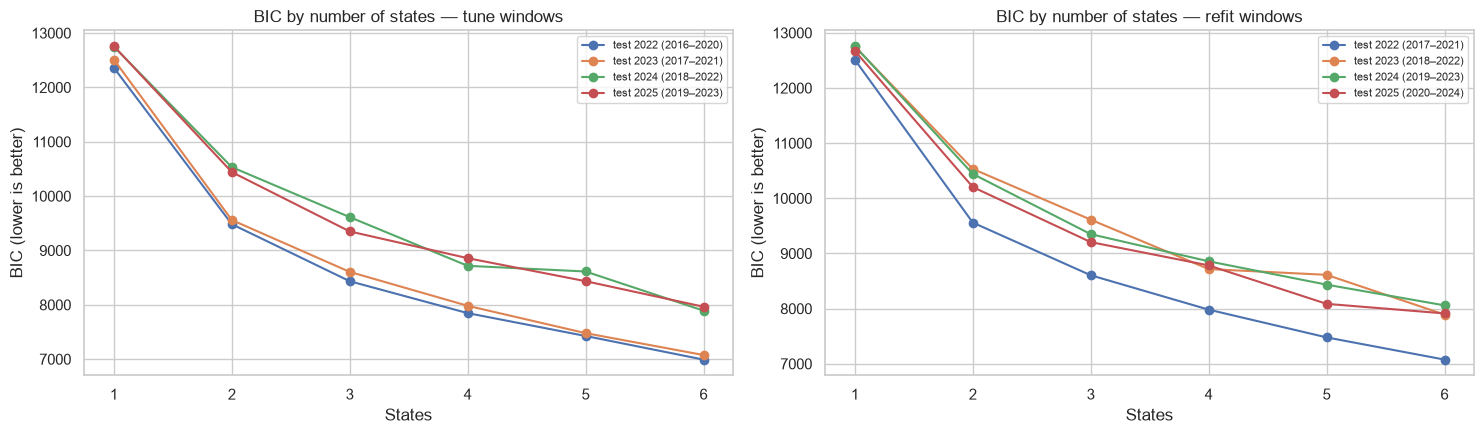

State profiles of the 3-state refit HMMs (original units):


,state (0 = calmest),activity,realized_vol,auction_share_dev,drawdown,share_of_training_days,expected_duration_days,test_year,phase,model
15,0,-0.0290,-2.5060,0.0960,-0.0040,0.4850,30.9890,2022,refit,k3
16,1,0.0090,-1.9690,0.0150,-0.0320,0.4160,20.9580,2022,refit,k3
17,2,0.2140,-1.0260,-0.1400,-0.1320,0.0980,30.4110,2022,refit,k3
33,0,-0.0340,-2.3170,0.0740,-0.0090,0.4760,52.0580,2023,refit,k3
34,1,0.0330,-1.7480,0.0110,-0.0440,0.3800,32.0690,2023,refit,k3
35,2,0.1230,-1.0830,-0.0900,-0.1240,0.1440,41.8800,2023,refit,k3
51,0,-0.0190,-2.1900,0.0480,-0.0040,0.4140,21.7180,2024,refit,k3
52,1,0.0230,-1.9650,0.0330,-0.0340,0.3970,16.5810,2024,refit,k3
53,2,0.0400,-1.2260,-0.0350,-0.1060,0.1890,39.7430,2024,refit,k3
69,0,-0.0000,-2.1400,0.0800,-0.0040,0.4150,21.5000,2025,refit,k3


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for (phase, ax) in zip(["tune", "refit"], axes):
    sub = bic_all[bic_all.phase == phase]
    for year, g in sub.groupby("test_year"):
        ax.plot(g.states, g.bic, marker="o", label=f"test {year} ({g.window.iloc[0]})")
    ax.set(title=f"BIC by number of states — {phase} windows", xlabel="States", ylabel="BIC (lower is better)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "hmm_bic_curves.png", bbox_inches="tight")
plt.show()

print("State profiles of the 3-state refit HMMs (original units):")
display(profiles[(profiles.model == "k3") & (profiles.phase == "refit")].round(3))

**Regimes over time.** Features from the last refit-phase HMM, fitted on 2020–2024. Dates after 2024 are out of sample for that HMM.

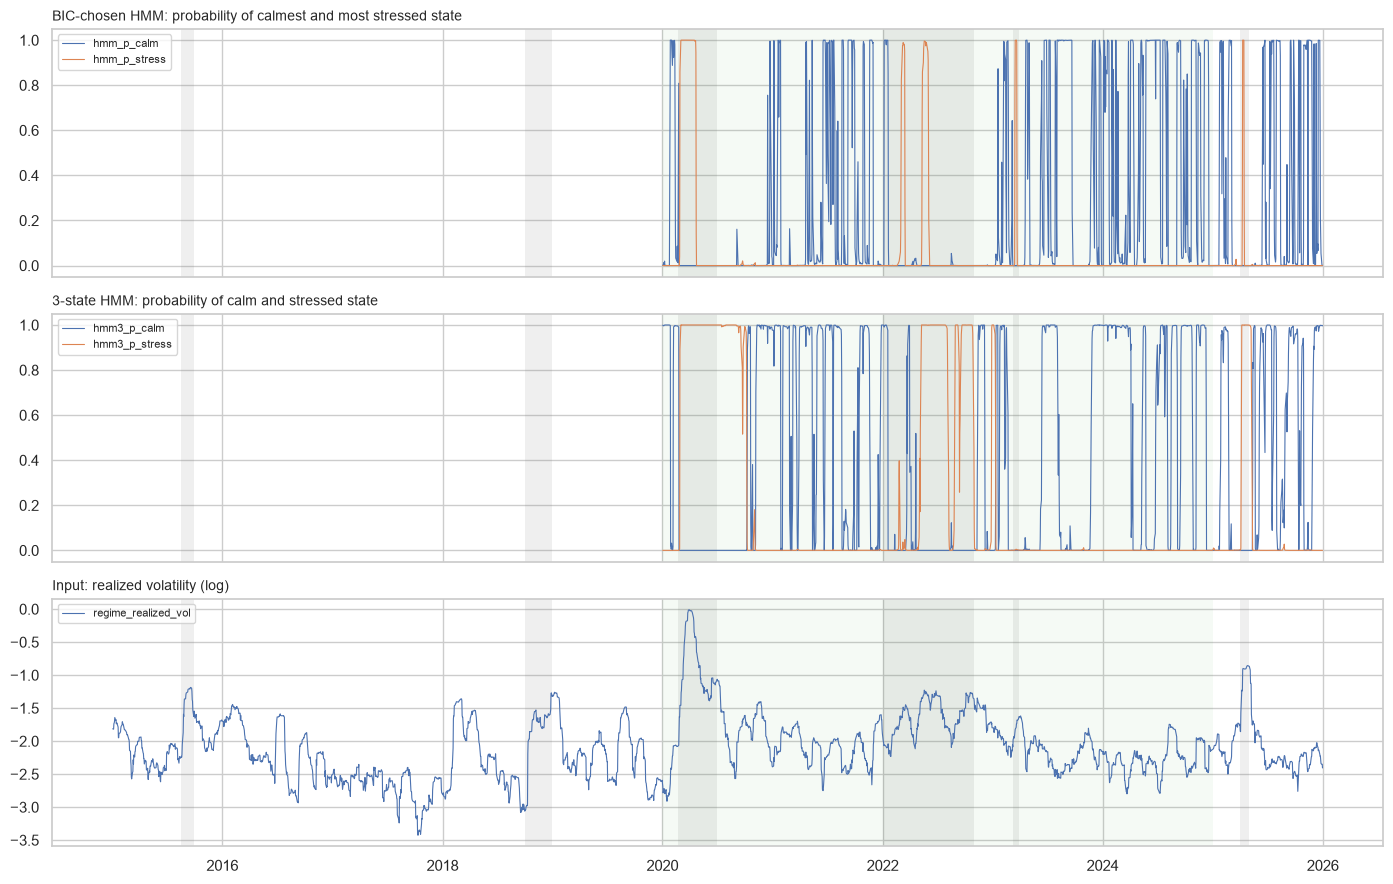

In [4]:
last = EXTRA[(max(cu.TEST_YEARS), "refit")].loc["2015-01-01":]
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, cols, title in [
    (axes[0], ["hmm_p_calm", "hmm_p_stress"], "BIC-chosen HMM: probability of calmest and most stressed state"),
    (axes[1], ["hmm3_p_calm", "hmm3_p_stress"], "3-state HMM: probability of calm and stressed state"),
    (axes[2], ["regime_realized_vol"], "Input: realized volatility (log)"),
]:
    for col in cols:
        ax.plot(last.index, last[col], lw=0.8, label=col)
    ru.shade_episodes(ax)
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2024-12-31"), color="green", alpha=0.04, lw=0)
    ax.set_title(title, loc="left", fontsize=10)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(OUT / "hmm_regimes_over_time.png", bbox_inches="tight")
plt.show()

**No-look-ahead check.** Refit the last fold's HMM features using only inputs up to a cutoff. Features on or before the cutoff must be identical to those computed with the full series.

In [5]:
start, end = phase_window(max(cu.TEST_YEARS), "refit")
cutoff = "2025-03-31"
truncated, *_ = ru.hmm_regime_features(inputs.loc[:cutoff], start, end, restarts=RESTARTS, seed=max(cu.TEST_YEARS))
full = EXTRA[(max(cu.TEST_YEARS), "refit")][ru.HMM_FEATURES]
gap = float((full.loc[:cutoff] - truncated[ru.HMM_FEATURES]).abs().max().max())
print(f"Largest change in features up to {cutoff} when later inputs are removed: {gap:.2e}")
assert gap < 1e-8, "HMM features use future information"

Largest change in features up to 2025-03-31 when later inputs are removed: 6.18e-12


## Candidates and rolling out-of-time run

About 45–60 minutes on an 8 GB M2.

In [6]:
N_JOBS = 6
NB16_PARAMS = {"objective": "regression", "learning_rate": 0.03, "min_child_samples": 500, "max_bin": 127,
               "colsample_bytree": 0.85, "reg_alpha": 0.1, "reg_lambda": 5.0}
LEAF_GRID = [{**NB16_PARAMS, "num_leaves": n} for n in (15, 31, 63)]


def lgbm_fit(x, y, x_val, y_val, config, seed):
    model = lgb.LGBMRegressor(n_estimators=3000, random_state=seed, n_jobs=N_JOBS, deterministic=True,
                              force_col_wise=True, verbosity=-1, **config)
    model.fit(x, y, eval_set=[(x_val, y_val)], eval_metric="rmse", callbacks=[lgb.early_stopping(100, verbose=False)])
    return model, int(model.best_iteration_)


def lgbm_refit(x, y, config, iterations, seed):
    return lgb.LGBMRegressor(n_estimators=iterations, random_state=seed, n_jobs=N_JOBS, deterministic=True,
                             force_col_wise=True, verbosity=-1, **config).fit(x, y)


def candidate(name, features):
    return {"name": name, "family": "LightGBM", "tier": "large", "features": features,
            "configs": LEAF_GRID[:1] if cu.SMOKE else LEAF_GRID, "fit": lgbm_fit, "refit": lgbm_refit,
            "importance": lambda m: m.booster_.feature_importance(importance_type="gain")}


CANDIDATES = [
    candidate("lgbm_control", cu.RATIO_SET),
    candidate("lgbm_plus_regime_inputs", cu.RATIO_SET + REGIME_INPUT_FEATURES),
    candidate("lgbm_plus_hmm_bic", cu.RATIO_SET + ru.HMM_FEATURES),
    candidate("lgbm_plus_hmm_k3", cu.RATIO_SET + HMM3_FEATURES),
    candidate("lgbm_plus_inputs_and_hmm_bic", cu.RATIO_SET + REGIME_INPUT_FEATURES + ru.HMM_FEATURES),
]
NAMES = [c["name"] for c in CANDIDATES]
metrics, validation, importance = cu.run_experiment(CANDIDATES, OUT, tag="hmm_regimes", extra=extra)
annual = metrics.pivot_table(index="candidate", columns="test_year", values="rmse_log")
display(annual.loc[[cu.CHAMPION] + NAMES])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[    26s] 2022 tier=large rows={'tune': 750000, 'validation': 150000, 'refit': 1000000}


[   169s]   lgbm_control: best config 1 (1505 iters, val rmse 0.5691)


[   441s]   lgbm_plus_regime_inputs: best config 2 (1472 iters, val rmse 0.5698)


[   712s]   lgbm_plus_hmm_bic: best config 2 (1330 iters, val rmse 0.5722)


... (27 outputs left out)

[ 34517s]   lgbm_plus_hmm_k3: best config 2 (591 iters, val rmse 0.4291)


[ 34738s]   lgbm_plus_inputs_and_hmm_bic: best config 0 (1334 iters, val rmse 0.4337)


[ 34800s] wrote 307,853 predictions for 2025


test_year,2022,2023,2024,2025
candidate,,,,
rolling5_residual_auction_calendar_liquidity,0.5338,0.4838,0.4460,0.4467
lgbm_control,0.5060,0.4559,0.4343,0.4236
lgbm_plus_regime_inputs,0.5103,0.4629,0.4353,0.4359
lgbm_plus_hmm_bic,0.5181,0.4589,0.4394,0.4333
lgbm_plus_hmm_k3,0.5078,0.4605,0.4332,0.4367
lgbm_plus_inputs_and_hmm_bic,0.5188,0.4597,0.4406,0.4342


## Results

In [7]:
# 1. The control should reproduce 16a's lgbm_61_ratios_large (same rows, features and settings).
m16a = pd.read_csv(LGBM_16A / "candidate_metrics.csv")
reference = m16a[m16a.candidate == "lgbm_61_ratios_large"].set_index("test_year").rmse_log
control = annual.loc["lgbm_control"]
check = pd.DataFrame({"16a lgbm_61_ratios_large": reference, "16d lgbm_control": control, "difference": control - reference})
display(check)

# 2. Effect of each addition, year by year.
steps = [("+ raw regime inputs", "lgbm_plus_regime_inputs"), ("+ HMM (BIC states)", "lgbm_plus_hmm_bic"),
         ("+ HMM (3 states)", "lgbm_plus_hmm_k3"), ("+ inputs and HMM (BIC)", "lgbm_plus_inputs_and_hmm_bic")]
effects = pd.DataFrame([
    {"change vs control": label, **{str(y): annual.loc[name, y] - control[y] for y in cu.TEST_YEARS},
     "mean_development_change": (annual.loc[name, cu.DEVELOPMENT_YEARS] - control[cu.DEVELOPMENT_YEARS]).mean()}
    for label, name in steps
])
effects.to_csv(OUT / "effects_vs_control.csv", index=False)
display(effects)

,16a lgbm_61_ratios_large,16d lgbm_control,difference
test_year,,,
2022,0.5060,0.5060,0.0000
2023,0.4559,0.4559,0.0000
2024,0.4343,0.4343,0.0000
2025,0.4236,0.4236,0.0000


,change vs control,2022,2023,2024,2025,mean_development_change
0,+ raw regime inputs,0.0043,0.0070,0.0010,0.0123,0.0041
1,+ HMM (BIC states),0.0121,0.0030,0.0050,0.0096,0.0067
2,+ HMM (3 states),0.0019,0.0046,-0.0011,0.0131,0.0018
3,+ inputs and HMM (BIC),0.0128,0.0038,0.0063,0.0105,0.0076


In [8]:
GLOB = str(OUT / "predictions" / "hmm_regimes_predictions_*.parquet")
vs_control, boot_control = cu.decision_table(metrics, GLOB, "lgbm_control", NAMES[1:])
vs_ridge, boot_ridge = cu.decision_table(metrics, GLOB, cu.CHAMPION, NAMES)
vs_inputs, _ = cu.decision_table(metrics, GLOB, "lgbm_plus_regime_inputs", ["lgbm_plus_hmm_bic", "lgbm_plus_hmm_k3", "lgbm_plus_inputs_and_hmm_bic"])
pd.concat([vs_control, vs_ridge, vs_inputs]).to_csv(OUT / "candidate_selection.csv", index=False)
pd.concat([boot_control.assign(reference="lgbm_control"), boot_ridge.assign(reference=cu.CHAMPION)]).to_csv(
    OUT / "date_block_bootstrap.csv", index=False)
print("Against the LightGBM control (did regime features help?)")
display(vs_control)
print("Against the raw-inputs model (does the HMM add anything beyond its own inputs?)")
display(vs_inputs)
print("Against the frozen ridge benchmark")
display(vs_ridge)

Against the LightGBM control (did regime features help?)


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,lgbm_plus_regime_inputs,lgbm_control,0.4695,0.4359,0.3539,0.0041,0.0070,0.0123,0.0019,0.0044,False,False,False,False
1,lgbm_plus_hmm_bic,lgbm_control,0.4721,0.4333,0.3546,0.0067,0.0121,0.0096,0.0034,0.0067,False,False,False,False
2,lgbm_plus_hmm_k3,lgbm_control,0.4672,0.4367,0.3524,0.0018,0.0046,0.0131,0.0011,0.0030,False,False,False,False
3,lgbm_plus_inputs_and_hmm_bic,lgbm_control,0.4730,0.4342,0.3563,0.0076,0.0128,0.0105,0.0040,0.0075,False,False,False,False
4,lgbm_control,lgbm_control,0.4654,0.4236,0.3507,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


Against the raw-inputs model (does the HMM add anything beyond its own inputs?)


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,lgbm_plus_hmm_bic,lgbm_plus_regime_inputs,0.4721,0.4333,0.3546,0.0026,0.0078,-0.0026,0.0015,0.0043,False,False,False,False
1,lgbm_plus_hmm_k3,lgbm_plus_regime_inputs,0.4672,0.4367,0.3524,-0.0023,-0.0021,0.0008,-0.0009,0.0014,True,True,False,False
2,lgbm_plus_inputs_and_hmm_bic,lgbm_plus_regime_inputs,0.4730,0.4342,0.3563,0.0035,0.0085,-0.0017,0.0021,0.0042,False,False,False,False
3,lgbm_plus_regime_inputs,lgbm_plus_regime_inputs,0.4695,0.4359,0.3539,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


Against the frozen ridge benchmark


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,lgbm_control,rolling5_residual_auction_calendar_liquidity,0.4654,0.4236,0.3507,-0.0225,-0.0117,-0.0230,-0.0099,-0.0054,True,True,True,True
1,lgbm_plus_regime_inputs,rolling5_residual_auction_calendar_liquidity,0.4695,0.4359,0.3539,-0.0184,-0.0107,-0.0107,-0.0080,-0.0044,True,True,True,True
2,lgbm_plus_hmm_bic,rolling5_residual_auction_calendar_liquidity,0.4721,0.4333,0.3546,-0.0158,-0.0067,-0.0134,-0.0065,-0.0028,True,True,True,True
3,lgbm_plus_hmm_k3,rolling5_residual_auction_calendar_liquidity,0.4672,0.4367,0.3524,-0.0207,-0.0128,-0.0100,-0.0089,-0.0046,True,True,True,True
4,lgbm_plus_inputs_and_hmm_bic,rolling5_residual_auction_calendar_liquidity,0.4730,0.4342,0.3563,-0.0148,-0.0054,-0.0125,-0.0059,-0.0021,True,True,True,True
5,rolling5_residual_auction_calendar_liquidity,rolling5_residual_auction_calendar_liquidity,0.4879,0.4467,0.3674,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


,total regime gain share
candidate,
lgbm_plus_hmm_bic,0.0844
lgbm_plus_hmm_k3,0.0747
lgbm_plus_inputs_and_hmm_bic,0.1139
lgbm_plus_regime_inputs,0.0791


,candidate,source_feature,gain_share
0,lgbm_plus_hmm_bic,hmm_entropy,0.0148
7,lgbm_plus_hmm_bic,hmm_regime_age,0.0145
6,lgbm_plus_hmm_bic,hmm_p_stress,0.0140
5,lgbm_plus_hmm_bic,hmm_p_calm,0.0106
1,lgbm_plus_hmm_bic,hmm_exp_activity,0.0093
2,lgbm_plus_hmm_bic,hmm_exp_auction_share_dev,0.0080
3,lgbm_plus_hmm_bic,hmm_exp_drawdown,0.0066
4,lgbm_plus_hmm_bic,hmm_exp_realized_vol,0.0059
8,lgbm_plus_hmm_bic,hmm_state_rank,0.0006
9,lgbm_plus_hmm_k3,hmm3_entropy,0.0194


,candidate,source_feature,rank
81,lgbm_plus_hmm_bic,hmm_entropy,15.0000
88,lgbm_plus_hmm_bic,hmm_regime_age,16.0000
87,lgbm_plus_hmm_bic,hmm_p_stress,17.0000
86,lgbm_plus_hmm_bic,hmm_p_calm,23.0000
82,lgbm_plus_hmm_bic,hmm_exp_activity,26.0000
83,lgbm_plus_hmm_bic,hmm_exp_auction_share_dev,29.0000
84,lgbm_plus_hmm_bic,hmm_exp_drawdown,31.0000
85,lgbm_plus_hmm_bic,hmm_exp_realized_vol,33.0000
89,lgbm_plus_hmm_bic,hmm_state_rank,62.0000
151,lgbm_plus_hmm_k3,hmm3_entropy,13.0000


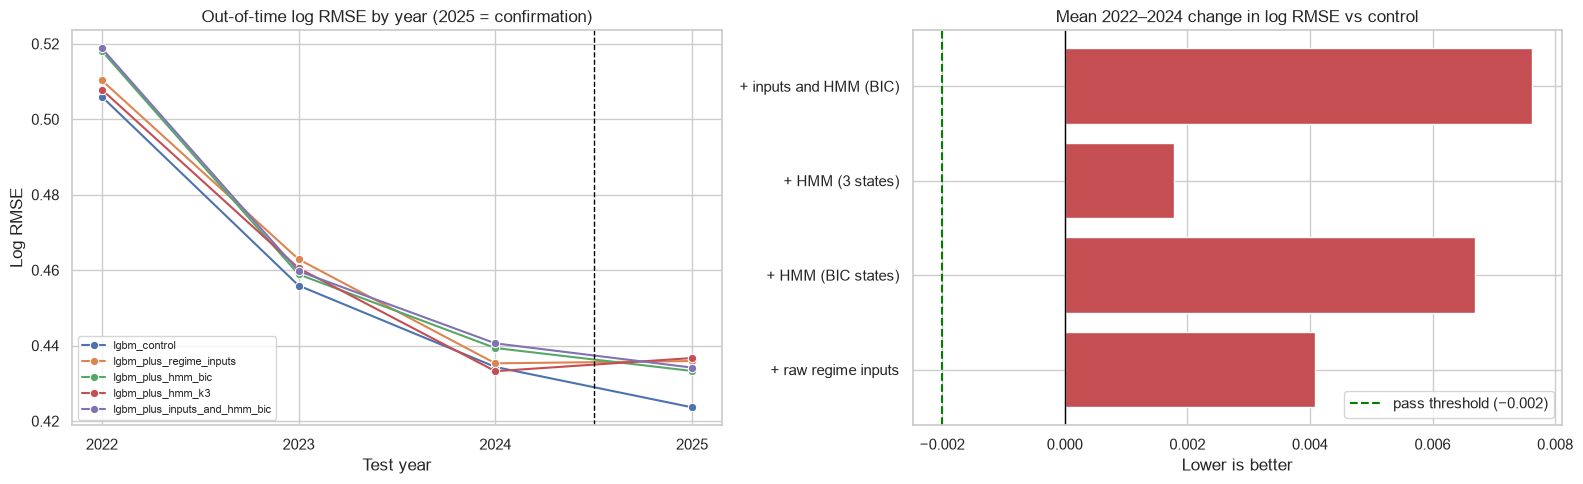

In [9]:
regime_cols = REGIME_INPUT_FEATURES + ru.HMM_FEATURES + HMM3_FEATURES
share = (importance[importance.source_feature.isin(regime_cols)]
         .groupby(["candidate", "source_feature"]).gain_share.mean().reset_index())
total = share.groupby("candidate").gain_share.sum().rename("total regime gain share")
display(total.to_frame())
display(share.sort_values(["candidate", "gain_share"], ascending=[True, False]))
importance_rank = (importance.groupby(["candidate", "source_feature"]).gain_share.mean()
                   .groupby(level=0).rank(ascending=False).rename("rank").reset_index())
display(importance_rank[importance_rank.source_feature.isin(regime_cols)].sort_values(["candidate", "rank"]).head(20))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot = metrics[metrics.candidate.isin(NAMES)]
sns.lineplot(data=plot, x="test_year", y="rmse_log", hue="candidate", marker="o", ax=axes[0])
axes[0].axvline(2024.5, color="black", ls="--", lw=1)
axes[0].set_xticks(cu.TEST_YEARS)  # whole years only; otherwise matplotlib picks 0.5 steps
axes[0].set(title="Out-of-time log RMSE by year (2025 = confirmation)", xlabel="Test year", ylabel="Log RMSE")
axes[0].legend(fontsize=8)
bars = effects.set_index("change vs control")["mean_development_change"]
axes[1].barh(bars.index, bars.values, color=["#4c72b0" if v < 0 else "#c44e52" for v in bars.values])
axes[1].axvline(-0.002, color="green", ls="--", label="pass threshold (−0.002)")
axes[1].axvline(0, color="black", lw=1)
axes[1].set(title="Mean 2022–2024 change in log RMSE vs control", xlabel="Lower is better")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT / "hmm_feature_effects.png", bbox_inches="tight")
plt.show()

## Conclusion data

In [10]:
summary = {
    "bic_states_chosen": {f"{row.test_year}_{row.phase}": int(row.states)
                          for row in bic_all[bic_all.chosen].itertuples()},
    "control_matches_16a": float(check.difference.abs().max()),
    "mean_development_change_vs_control": effects.set_index("change vs control")["mean_development_change"].round(5).to_dict(),
    "passes_gate_vs_control": vs_control.loc[vs_control.passes_gate == True, "candidate"].tolist(),
    "passes_gate_vs_frozen_ridge": vs_ridge.loc[vs_ridge.passes_gate == True, "candidate"].tolist(),
    "smoke_mode": cu.SMOKE,
}
with open(OUT / "summary.json", "w") as handle:
    json.dump(summary, handle, indent=2, default=str)
display(summary)

{'bic_states_chosen': {'2022_tune': 6,
  '2022_refit': 6,
  '2023_tune': 6,
  '2023_refit': 6,
  '2024_tune': 6,
  '2024_refit': 6,
  '2025_tune': 6,
  '2025_refit': 6},
 'control_matches_16a': 0.0,
 'mean_development_change_vs_control': {'+ raw regime inputs': 0.00409,
  '+ HMM (BIC states)': 0.0067,
  '+ HMM (3 states)': 0.00178,
  '+ inputs and HMM (BIC)': 0.00763},
 'passes_gate_vs_control': [],
 'passes_gate_vs_frozen_ridge': ['lgbm_control',
  'lgbm_plus_regime_inputs',
  'lgbm_plus_hmm_bic',
  'lgbm_plus_hmm_k3',
  'lgbm_plus_inputs_and_hmm_bic'],
 'smoke_mode': False}

## Conclusion

Figures are from the full run (large tier, 4 rolling folds). A change is new log RMSE minus control log RMSE, so **positive means worse**.

| Candidate | 2022 | 2023 | 2024 | Mean change 2022–2024 | 2025 (confirmation) | Passes gate vs control |
|---|---|---|---|---|---|---|
| + raw regime inputs | +0.0043 | +0.0070 | +0.0010 | **+0.0041** | +0.0123 | no |
| + HMM (BIC states) | +0.0121 | +0.0030 | +0.0050 | **+0.0067** | +0.0096 | no |
| + HMM (3 states) | +0.0019 | +0.0046 | −0.0011 | **+0.0018** | +0.0131 | no |
| + inputs and HMM (BIC) | +0.0128 | +0.0038 | +0.0063 | **+0.0076** | +0.0105 | no |

**1. Regime features make the model worse, not better.**
- Every variant raises out-of-time error in the development years and in 2025.
- The control reproduces 16a's `lgbm_61_ratios_large` exactly (difference 0.0 in every year), so the comparison is like for like.
- All variants still beat the frozen ridge, but only because the LightGBM base is strong. The control beats ridge by more.

**2. The HMM adds nothing beyond its own inputs.**
- The BIC-state HMM is worse than giving the model the 4 raw inputs directly (+0.0026).
- The 3-state HMM is slightly better than the raw inputs (−0.0023), but the paired bootstrap does not support it, and it is still worse than the control.

**3. The models used the features heavily, which shows overfitting.**
- Regime features took 6–13% of total split gain, yet out-of-time error rose. The trees found them useful in training, and that did not carry over to new years.
- A regime feature has one value per day, shared by about 1,300 stocks. Inside a 5-year training window, the tree can use it to recognise particular periods and learn those periods' typical residual levels. A new year brings new periods, so those learned levels are wrong.
- The stock-level lag features (for example `abnormal_volume_lag1` and the ratio features) already carry most market-wide shifts, at the level of each stock.

**4. BIC is unstable here.**
- BIC picked the maximum of 6 states in every window. That is the bias toward more states caused by smoothed, autocorrelated inputs.
- The 6-state solutions also change between the tuning fit and the refit (compare the state profiles). The hyperparameters and early stopping are tuned on one state definition and applied to another, which adds noise.
- The more stable 3-state model is the least harmful, which fits this explanation.

**5. This matches Notebook 16c.** The hindsight ceiling for point accuracy there was about 0.001 log RMSE, below the 0.002 pass threshold. This notebook shows that, in practice, forward-filtered regimes cost more than that ceiling.

**Decision:** do not add HMM or raw regime features to the LightGBM model. The champion stays `lgbm_61_ratios_large` / `_tuned` from Notebook 16a. If regimes are revisited, they are more defensible for recalibrating prediction intervals than as point-forecast features.